<a href="https://colab.research.google.com/github/kheisaa196-max/Praktikum-1-6AVD/blob/main/KKA_3_Praktikum_1_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
df = pd.read_csv('penjualan_nusantaramart - penjualan_nusantaramart.csv')
print(df.head()) # lihat 5 baris pertama
print(df.info()) # tipe data & jumlah data kosong
print(df.describe()) # ringkasan statistik
# rata-rata total pembelian per kategori produk
rata_kategori = df.groupby('kategori_produk')['total'].mean()
print(rata_kategori.sort_values(ascending=False))

   order_id     tanggal    kategori_produk        nama_produk   wilayah  \
0      1146  2026-01-03           Olahraga        Matras Yoga    Malang   
1      1166  2026-01-05            Fashion       Celana Jeans  Surabaya   
2      1190  2026-01-05          Kesehatan   Masker Medis Box  Semarang   
3      1219  2026-01-08  Makanan & Minuman  Kopi Kemasan 200g   Bandung   
4      1133  2026-01-10            Fashion         Tas Ransel  Surabaya   

   jumlah  harga_satuan   total metode_pembayaran  rating_pelanggan  
0       5         90000  450000          E-Wallet                 4  
1       5        175000  875000     Transfer Bank                 5  
2       4         30000  120000      Kartu Kredit                 3  
3       4         28000  112000          E-Wallet                 3  
4       4        130000  520000      Kartu Kredit                 4  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 10 columns):
 #   Column             

Kategori produk dengan rata-rata transaksi tertinggi:

Elektronik (dengan rata-rata nilai transaksi sekitar Rp363.541,67).
Pengecekan data kosong (missing value) dari df.info():

Tidak ada. Cara mengeceknya adalah dengan melihat jumlah Non-Null Count pada setiap kolom (semuanya tertulis 220 non-null), yang nilainya sama persis dengan total entri data (RangeIndex: 220 entries).
Perbandingan nilai mean dan median kolom total:

Mean (Rp238.486) jauh lebih besar daripada Median/50% (Rp125.000). Hal ini menunjukkan bahwa sebaran data memiliki kemiringan positif (skewed ke kanan / right-skewed), yang berarti terdapat beberapa transaksi dengan nilai sangat besar (outlier) yang menarik nilai rata-rata ke atas.

/tmp/ipykernel_3326/1140824476.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')


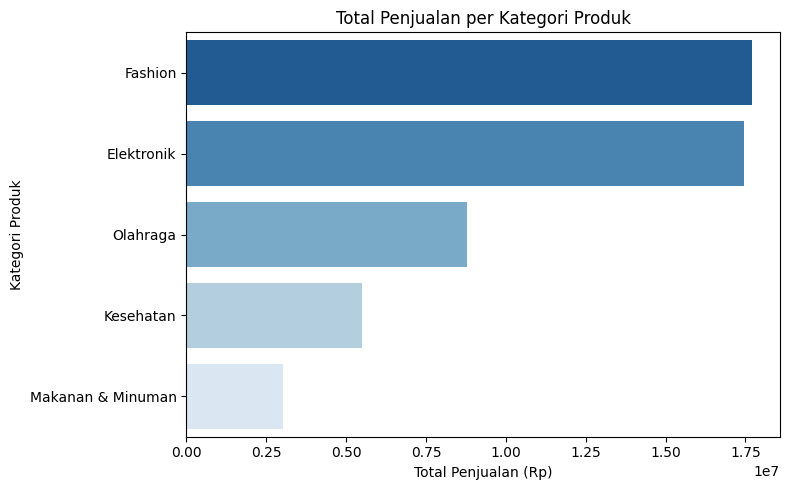

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)
plt.figure(figsize=(8,5))
sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')

plt.tight_layout()
plt.show()

Kategori penyumbang penjualan tertinggi dan terendah:

Tertinggi: Fashion (diikuti sangat ketat oleh Elektronik).
Terendah: Makanan & Minuman.
Rekomendasi bisnis untuk manajer Nusantara Mart:

Optimalkan Stok & Promosi Fashion & Elektronik: Karena kedua kategori ini adalah mesin pendapatan utama, pastikan ketersediaan stok selalu terjaga dan buat promo paket bundling untuk meningkatkan penjualan lebih lanjut.
Evaluasi Kategori Makanan & Minuman: Selidiki penyebab rendahnya penjualan (apakah karena variasi produk sedikit, harga kurang kompetitif, atau promosi minim) dan lakukan kurasi ulang produk yang lebih diminati konsumen.

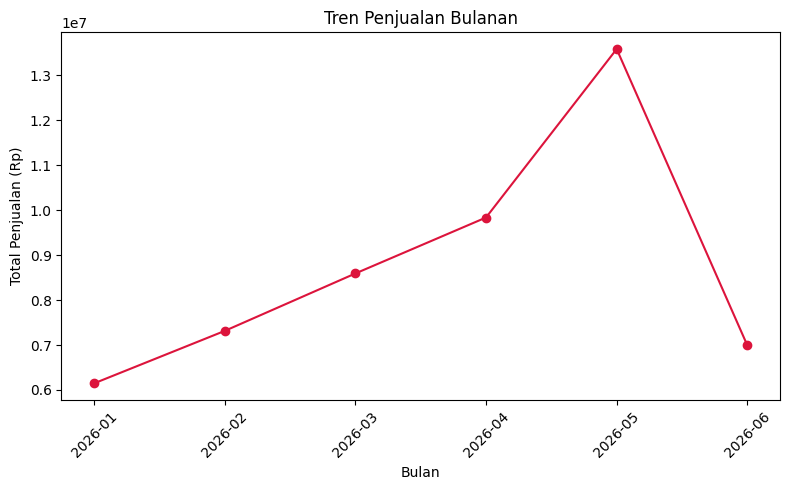

In [ ]:
df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')
tren_bulanan = df.groupby('bulan')['total'].sum()
plt.figure(figsize=(8,5))
plt.plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o', color='crimson')
plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Bulan dengan penjualan tertinggi: Mei 2026 (mencapai Rp13.585.000). Kemungkinan penyebabnya adalah faktor musiman (seasonal) seperti persiapan menyambut hari raya atau liburan sekolah yang meningkatkan daya beli masyarakat.
Tren penjualan: Cenderung fluktuatif dengan pola meningkat konsisten dari Januari hingga puncaknya di Mei, kemudian mengalami penurunan signifikan pada bulan Juni.

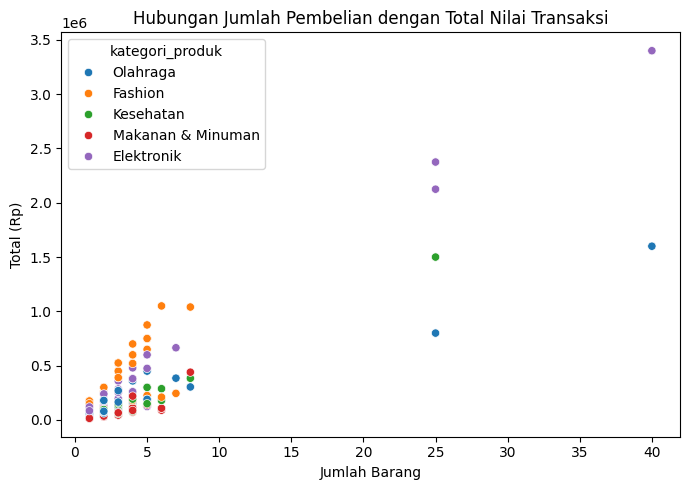

In [ ]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='jumlah', y='total', hue='kategori_produk')
plt.title('Hubungan Jumlah Pembelian dengan Total Nilai Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')
plt.tight_layout()
plt.show()

1. Apakah terlihat pola hubungan antara jumlah barang dan total nilai transaksi?
Ya, terlihat pola hubungan positif antara jumlah barang yang dibeli dan total nilai transaksi. Artinya, semakin banyak jumlah barang yang dibeli, total nilai transaksi cenderung semakin besar. Namun, nilai transaksi juga dipengaruhi oleh kategori produk dan harga setiap barang, sehingga tidak semua titik mengikuti pola yang sama.
2. Apakah ada titik data yang terlihat jauh dari pola umum (kemungkinan outlier)?
Ya, terdapat beberapa titik data yang terlihat jauh dari kumpulan data lainnya, yaitu:
- Elektronik (ungu): jumlah pembelian sekitar 25 barang dengan total transaksi sekitar Rp2.120.000 dan Rp2.380.000, serta 40 barang dengan total sekitar Rp3.400.000.
- Kesehatan (hijau): jumlah pembelian sekitar 25 barang dengan total transaksi sekitar Rp1.500.000.
- Olahraga (biru): jumlah pembelian sekitar 25 barang dengan total sekitar Rp800.000 dan 40 barang dengan total sekitar Rp1.600.000.


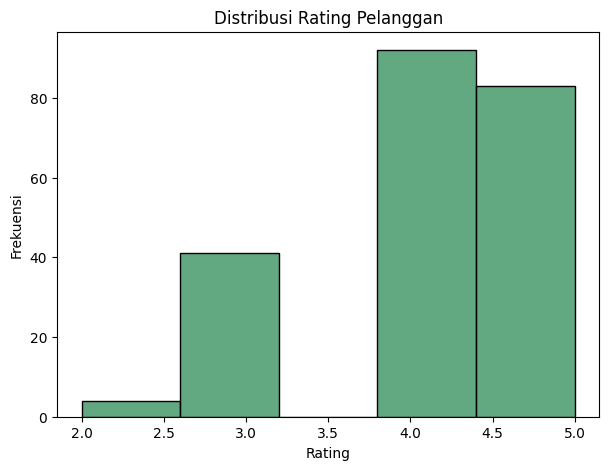

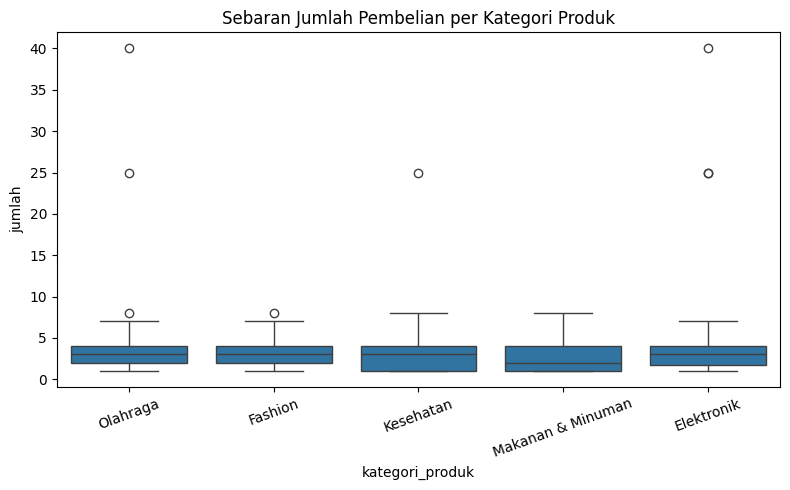

In [ ]:
# Histogram distribusi rating pelanggan
plt.figure(figsize=(7,5))
sns.histplot(df['rating_pelanggan'], bins=5, color='seagreen')
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()
# Boxplot jumlah pembelian per kategori (deteksi outlier)
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='kategori_produk', y='jumlah')
plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

1. Bentuk distribusi rating cenderung tinggi
 * Sebagian besar pelanggan memberikan penilaian pada rentang tinggi, yaitu rating **4.0 – 4.4** (frekuensi terbanyak, >90) dan rating **4.5 – 5.0** (frekuensi terbanyak kedua, >80).
  * Hanya sebagian kecil pelanggan yang memberikan rating netral (3.0 sebesar ~40) dan sangat sedikit yang memberikan rating rendah (2.0 – 2.5).
  * **Kesimpulan:** Mayoritas pelanggan merasa sangat puas dengan produk dan layanan Nusantara Mart.

  2. Analisis Distribusi Rating Pelanggan (Histogram)
* **Bentuk Distribusi:** **Cenderung Tinggi** (*skewed to the right*).
* **Penjelasan:** Mayoritas pelanggan memberikan nilai tinggi di rentang **4.0 – 5.0** (frekuensi terbanyak). Hal ini menunjukkan kepuasan pelanggan secara umum sangat baik.

3. Analisis Sebaran & Outlier Pembelian (Boxplot)
* **Kategori dengan Outlier Ekstrem:**
  * **Olahraga & Elektronik:** Memiliki pencilan ekstrem hingga jumlah **25** dan **40** unit.
  * **Kesehatan:** Memiliki pencilan di jumlah **25** unit.
  * **Fashion:** Memiliki pencilan kecil di jumlah **8** unit.
  * **Makanan & Minuman:** **Tidak ada** pencilan (sebaran normal 1–8 unit).
* **Penyebab Outlier:** Pembelian partai besar oleh *reseller*/grosir, adanya promo diskon kuantitas, atau kebutuhan instansi/acara tertentu.

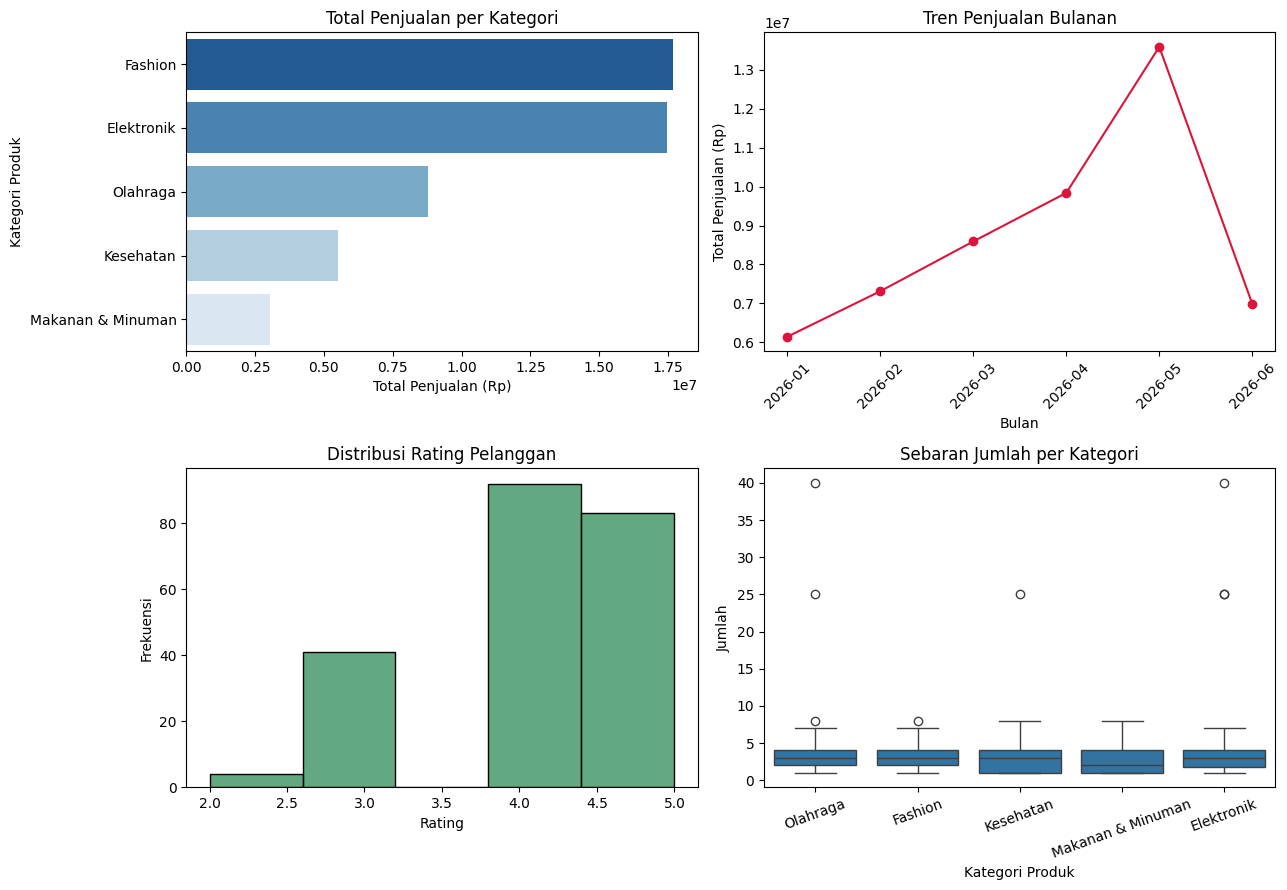

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Membaca data dan memproses kolom tanggal agar sel bersifat self-contained
df = pd.read_csv('penjualan_nusantaramart - penjualan_nusantaramart.csv')
df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')

# Definisikan variabel yang dibutuhkan untuk visualisasi
total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)
tren_bulanan = df.groupby('bulan')['total'].sum()

fig, axes = plt.subplots(2, 2, figsize=(13,9))

# Subplot 1: Total Penjualan per Kategori
sns.barplot(x=total_kategori.values, y=total_kategori.index, ax=axes[0,0], palette='Blues_r', hue=total_kategori.index, legend=False)
axes[0,0].set_title('Total Penjualan per Kategori')
axes[0,0].set_xlabel('Total Penjualan (Rp)')
axes[0,0].set_ylabel('Kategori Produk')

# Subplot 2: Tren Penjualan Bulanan
axes[0,1].plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o', color='crimson')
axes[0,1].set_title('Tren Penjualan Bulanan')
axes[0,1].set_xlabel('Bulan')
axes[0,1].set_ylabel('Total Penjualan (Rp)')
axes[0,1].tick_params(axis='x', rotation=45)

# Subplot 3: Distribusi Rating Pelanggan
sns.histplot(df['rating_pelanggan'], bins=5, ax=axes[1,0], color='seagreen')
axes[1,0].set_title('Distribusi Rating Pelanggan')
axes[1,0].set_xlabel('Rating')
axes[1,0].set_ylabel('Frekuensi')

# Subplot 4: Sebaran Jumlah per Kategori
sns.boxplot(data=df, x='kategori_produk', y='jumlah', ax=axes[1,1])
axes[1,1].set_title('Sebaran Jumlah per Kategori')
axes[1,1].set_xlabel('Kategori Produk')
axes[1,1].set_ylabel('Jumlah')
axes[1,1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

Keuntungan menyajikan beberapa grafik dalam satu dashboard adalah memudahkan kita melihat dan membandingkan data secara bersamaan. Kita dapat mengetahui kategori dengan penjualan tertinggi, tren penjualan setiap bulan, distribusi rating pelanggan, dan jumlah produk per kategori dengan lebih cepat. Selain itu, dashboard membuat analisis lebih efisien, memudahkan pengambilan keputusan, dan membantu menemukan pola atau masalah tanpa harus membuka grafik satu per satu.